Occupancy Prediction: 30-Minute-Ahead Classification
Goal: Predict the occupancy level of each room 30 minutes into the future using the cleaned 5-minute sensor table.

Models compared:
- Persistence baseline: current occupancy level
- Logistic Regression
- Random Forest
- HistGradientBoosting
- XGBoost 
- CatBoost 

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

%pip install numpy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
DATA_PATH = Path("../data/processed/model_table_5min.csv")
CLASS_LABELS = [0, 1, 2, 3, 4]
CLASS_NAMES = ["Empty", "Low", "Moderate", "High", "Very high"]

print("Notebook working directory:", Path.cwd())
print("Dataset path:", DATA_PATH.resolve())

Note: you may need to restart the kernel to use updated packages.
Notebook working directory: c:\Users\leena\OneDrive\Desktop\adaptive-district-backbone\notebooks
Dataset path: C:\Users\leena\OneDrive\Desktop\adaptive-district-backbone\data\processed\model_table_5min.csv


In [2]:
if not DATA_PATH.exists():
    alternatives = [
        Path("data/processed/model_table_5min.csv"),
        Path("../data/model_table_5min.csv"),
        Path("model_table_5min.csv"),
    ]
    found = next((p for p in alternatives if p.exists()), None)
    if found is None:
        raise FileNotFoundError(
            f"Could not find {DATA_PATH}. Update DATA_PATH to the location of model_table_5min.csv."
        )
    DATA_PATH = found

data = pd.read_csv(DATA_PATH)
print("Shape:", data.shape)
display(data.head())
print("\nColumns:")
print(data.columns.tolist())

Shape: (36432, 58)


,DayId,bin,occ,cam1_fw,cam1_bw,cam2_fw,cam2_bw,co2,temperature,humidity,...,humidity_diff,cam1_fw_last15,cam1_bw_last15,cam2_fw_last15,cam2_bw_last15,target,capacity,event_day,occ_ratio,is_lecture
0,0,6,0.0,0.0,0.0,0.0,0.0,482.880005,23.6,52.941177,...,0.0,0.0,0.0,0.0,0.0,0.0,84,0,0.0,1
1,0,7,0.0,0.0,0.0,0.0,0.0,480.000000,23.6,52.941177,...,0.0,0.0,0.0,0.0,0.0,0.0,84,0,0.0,1
2,0,8,0.0,0.0,0.0,0.0,0.0,475.839996,23.6,52.941177,...,0.0,0.0,0.0,0.0,0.0,0.0,84,0,0.0,1
3,0,9,0.0,0.0,0.0,0.0,0.0,478.720001,23.6,52.941177,...,0.0,0.0,0.0,0.0,0.0,0.0,84,0,0.0,1
4,0,10,0.0,0.0,0.0,0.0,0.0,473.920013,23.6,52.941177,...,0.0,0.0,0.0,0.0,0.0,0.0,84,0,0.0,1



Columns:
['DayId', 'bin', 'occ', 'cam1_fw', 'cam1_bw', 'cam2_fw', 'cam2_bw', 'co2', 'temperature', 'humidity', 'illuminance', 'vav', 'co2_age', 'temperature_age', 'humidity_age', 'illuminance_age', 'vav_age', 'room', 'workday', 'month', 'hour_sin', 'hour_cos', 'occ_lag1', 'occ_lag2', 'occ_lag3', 'occ_lag6', 'co2_lag1', 'co2_lag2', 'co2_lag3', 'co2_lag6', 'temperature_lag1', 'temperature_lag2', 'temperature_lag3', 'temperature_lag6', 'humidity_lag1', 'humidity_lag2', 'humidity_lag3', 'humidity_lag6', 'illuminance_lag1', 'illuminance_lag2', 'illuminance_lag3', 'illuminance_lag6', 'vav_lag1', 'vav_lag2', 'vav_lag3', 'vav_lag6', 'co2_diff', 'temperature_diff', 'humidity_diff', 'cam1_fw_last15', 'cam1_bw_last15', 'cam2_fw_last15', 'cam2_bw_last15', 'target', 'capacity', 'event_day', 'occ_ratio', 'is_lecture']


In [3]:
required = {"DayId", "room", "occ", "target", "capacity"}
missing = required - set(data.columns)
if missing:
    raise ValueError(f"Missing expected columns: {sorted(missing)}")

print("Unique days:", data["DayId"].nunique())
print("Rooms:", sorted(data["room"].dropna().unique().tolist()))
print("Missing values:", int(data.isna().sum().sum()))
print("\nTarget occupancy summary:")
display(data["target"].describe().to_frame())

Unique days: 44
Rooms: [1, 2, 3]
Missing values: 0

Target occupancy summary:


,target
count,36432.000000
mean,5.568319
std,11.269965
min,0.000000
25%,0.000000
50%,1.000000
75%,5.000000
max,78.800000


In [4]:
occupancy_ratio_future = data["target"] / data["capacity"]

data["target_class"] = pd.cut(
    occupancy_ratio_future,
    bins=[-0.001, 0, 0.25, 0.50, 0.75, np.inf],
    labels=CLASS_LABELS,
    include_lowest=True,
).astype("Int64")

# Remove rows where the target or capacity could not be used.
data = data.dropna(subset=["target_class", "DayId", "capacity"]).copy()
data["target_class"] = data["target_class"].astype(int)

display(
    data["target_class"]
    .value_counts()
    .reindex(CLASS_LABELS, fill_value=0)
    .rename(index=dict(zip(CLASS_LABELS, CLASS_NAMES)))
    .to_frame("rows")
)
display(
    (data["target_class"].value_counts(normalize=True)
     .reindex(CLASS_LABELS, fill_value=0) * 100)
    .rename(index=dict(zip(CLASS_LABELS, CLASS_NAMES)))
    .round(2).to_frame("percent")
)

,rows
target_class,
Empty,16523
Low,13301
Moderate,3983
High,1883
Very high,742


,percent
target_class,
Empty,45.35
Low,36.51
Moderate,10.93
High,5.17
Very high,2.04


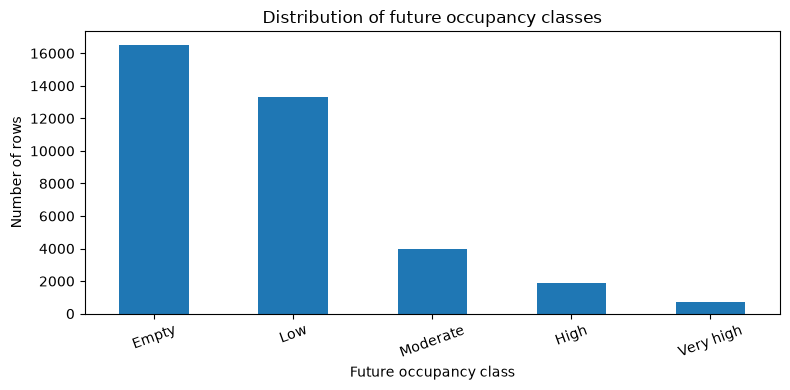

In [5]:
class_counts = data["target_class"].value_counts().reindex(CLASS_LABELS, fill_value=0)
ax = class_counts.rename(index=dict(zip(CLASS_LABELS, CLASS_NAMES))).plot(
    kind="bar", figsize=(8, 4), rot=20
)
ax.set_xlabel("Future occupancy class")
ax.set_ylabel("Number of rows")
ax.set_title("Distribution of future occupancy classes")
plt.tight_layout()
plt.show()

In [6]:
leakage_or_id_cols = {
    "target", "target_class", "event_day", "DayId",
    "occ_future", "target_future", "future_occupancy"
}
feature_cols = [
    c for c in data.columns
    if c not in leakage_or_id_cols
    and pd.api.types.is_numeric_dtype(data[c])
]

# Keep only features with at least one non-missing value.
feature_cols = [c for c in feature_cols if data[c].notna().any()]

X = data[feature_cols].copy()
y = data["target_class"].astype(int)
groups = data["DayId"]

print("Number of features:", len(feature_cols))
print(feature_cols)
print("\nTarget classes:", sorted(y.unique()))

Number of features: 55
['bin', 'occ', 'cam1_fw', 'cam1_bw', 'cam2_fw', 'cam2_bw', 'co2', 'temperature', 'humidity', 'illuminance', 'vav', 'co2_age', 'temperature_age', 'humidity_age', 'illuminance_age', 'vav_age', 'room', 'workday', 'month', 'hour_sin', 'hour_cos', 'occ_lag1', 'occ_lag2', 'occ_lag3', 'occ_lag6', 'co2_lag1', 'co2_lag2', 'co2_lag3', 'co2_lag6', 'temperature_lag1', 'temperature_lag2', 'temperature_lag3', 'temperature_lag6', 'humidity_lag1', 'humidity_lag2', 'humidity_lag3', 'humidity_lag6', 'illuminance_lag1', 'illuminance_lag2', 'illuminance_lag3', 'illuminance_lag6', 'vav_lag1', 'vav_lag2', 'vav_lag3', 'vav_lag6', 'co2_diff', 'temperature_diff', 'humidity_diff', 'cam1_fw_last15', 'cam1_bw_last15', 'cam2_fw_last15', 'cam2_bw_last15', 'capacity', 'occ_ratio', 'is_lecture']

Target classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


In [7]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
groups_train, groups_test = groups.iloc[train_idx], groups.iloc[test_idx]

assert set(groups_train).isdisjoint(set(groups_test))

print("Train rows:", len(train_idx), "| Train days:", groups_train.nunique())
print("Test rows:", len(test_idx), "| Test days:", groups_test.nunique())
print("Train days:", sorted(groups_train.unique().tolist()))
print("Test days:", sorted(groups_test.unique().tolist()))
print("\nTraining class counts:")
display(y_train.value_counts().reindex(CLASS_LABELS, fill_value=0).rename(index=dict(zip(CLASS_LABELS, CLASS_NAMES))).to_frame("rows"))
print("\nTest class counts:")
display(y_test.value_counts().reindex(CLASS_LABELS, fill_value=0).rename(index=dict(zip(CLASS_LABELS, CLASS_NAMES))).to_frame("rows"))

Train rows: 28980 | Train days: 35
Test rows: 7452 | Test days: 9
Train days: [0, 1, 2, 3, 5, 6, 7, 9, 10, 11, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 26, 27, 28, 29, 30, 31, 32, 33, 35, 38, 39, 41, 42, 43]
Test days: [4, 8, 12, 24, 25, 34, 36, 37, 40]

Training class counts:


,rows
target_class,
Empty,13456
Low,10427
Moderate,3222
High,1333
Very high,542



Test class counts:


,rows
target_class,
Empty,3067
Low,2874
Moderate,761
High,550
Very high,200


In [8]:
def occupancy_to_class(occupancy, capacity):
    ratio = occupancy / capacity
    return pd.cut(
        ratio,
        bins=[-0.001, 0, 0.25, 0.50, 0.75, np.inf],
        labels=CLASS_LABELS,
        include_lowest=True
    ).astype("Int64").astype(int)

baseline_pred = occupancy_to_class(
    data.iloc[test_idx]["occ"],
    data.iloc[test_idx]["capacity"]
)

def score_predictions(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(y_true, y_pred, labels=CLASS_LABELS, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_true, y_pred, labels=CLASS_LABELS, average="weighted", zero_division=0),
    }

results = [score_predictions("Persistence baseline", y_test, baseline_pred)]
pd.DataFrame(results).round(3)

,Model,Accuracy,Balanced accuracy,Macro F1,Weighted F1
0,Persistence baseline,0.821,0.709,0.709,0.821


In [9]:
models = {
    "Logistic Regression": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        )
    ),
    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(
            n_estimators=350,
            min_samples_leaf=3,
            class_weight="balanced_subsample",
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    ),
    "HistGradientBoosting": make_pipeline(
        SimpleImputer(strategy="median"),
        HistGradientBoostingClassifier(
            max_iter=180,
            learning_rate=0.08,
            max_leaf_nodes=15,
            l2_regularization=1.0,
            random_state=RANDOM_STATE
        )
    ),
}

# Optional XGBoost model
try:
    from xgboost import XGBClassifier
    models["XGBoost"] = make_pipeline(
        SimpleImputer(strategy="median"),
        XGBClassifier(
            n_estimators=300,
            max_depth=4,
            learning_rate=0.04,
            subsample=0.85,
            colsample_bytree=0.85,
            objective="multi:softprob",
            eval_metric="mlogloss",
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    )
    print("XGBoost available.")
except ImportError:
    print("XGBoost not installed; skipping it. Optional: %pip install xgboost")

# Optional CatBoost model
try:
    from catboost import CatBoostClassifier
    models["CatBoost"] = make_pipeline(
        SimpleImputer(strategy="median"),
        CatBoostClassifier(
            iterations=350,
            depth=5,
            learning_rate=0.04,
            loss_function="MultiClass",
            verbose=False,
            random_seed=RANDOM_STATE,
            auto_class_weights="Balanced"
        )
    )
    print("CatBoost available.")
except ImportError:
    print("CatBoost not installed; skipping it. Optional: %pip install catboost")

print("\nModels to train:", list(models.keys()))

XGBoost available.
CatBoost available.

Models to train: ['Logistic Regression', 'Random Forest', 'HistGradientBoosting', 'XGBoost', 'CatBoost']


In [10]:
fitted_models = {}
model_predictions = {}
results = [score_predictions("Persistence baseline", y_test, baseline_pred)]

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    pred = np.asarray(pred).reshape(-1).astype(int)

    fitted_models[name] = model
    model_predictions[name] = pred
    results.append(score_predictions(name, y_test, pred))

results_df = pd.DataFrame(results).sort_values("Macro F1", ascending=False).reset_index(drop=True)
display(results_df.round(3))

Training Logistic Regression...
Training Random Forest...
Training HistGradientBoosting...
Training XGBoost...
Training CatBoost...


,Model,Accuracy,Balanced accuracy,Macro F1,Weighted F1
0,CatBoost,0.825,0.729,0.717,0.828
1,Persistence baseline,0.821,0.709,0.709,0.821
2,Random Forest,0.833,0.696,0.700,0.834
3,XGBoost,0.833,0.670,0.685,0.830
4,HistGradientBoosting,0.828,0.657,0.673,0.826
5,Logistic Regression,0.772,0.689,0.667,0.772


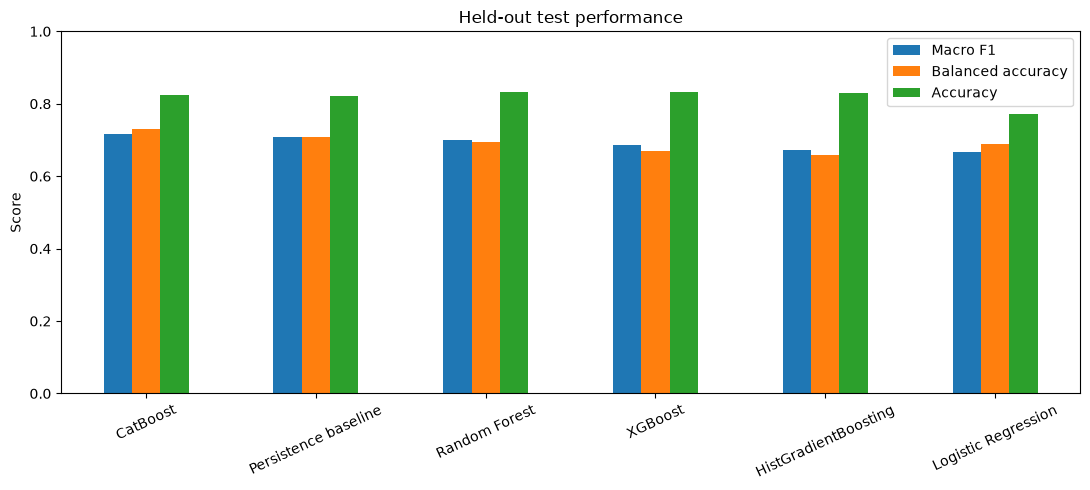

In [11]:
plot_df = results_df.set_index("Model")[["Macro F1", "Balanced accuracy", "Accuracy"]]
ax = plot_df.plot(kind="bar", figsize=(11, 5), ylim=(0, 1))
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.set_title("Held-out test performance")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

Best model by test macro F1: CatBoost

              precision    recall  f1-score   support

       Empty       0.92      0.91      0.91      3067
         Low       0.87      0.81      0.84      2874
    Moderate       0.60      0.67      0.64       761
        High       0.57      0.70      0.63       550
   Very high       0.59      0.55      0.57       200

    accuracy                           0.82      7452
   macro avg       0.71      0.73      0.72      7452
weighted avg       0.83      0.82      0.83      7452



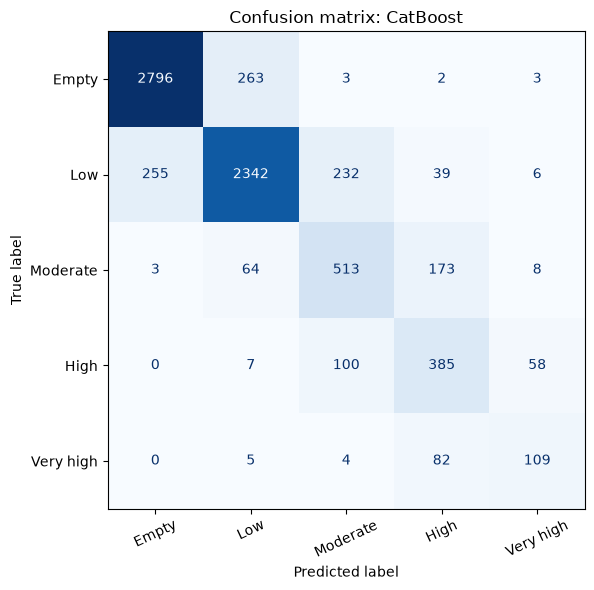

In [18]:
ml_results = results_df[results_df["Model"] != "Persistence baseline"]
if ml_results.empty:
    raise RuntimeError("No ML models were trained.")
best_name = ml_results.iloc[0]["Model"]
best_pred = model_predictions[best_name]

print("Best model by test macro F1:", best_name)
print()
print(classification_report(
    y_test,
    best_pred,
    labels=CLASS_LABELS,
    target_names=CLASS_NAMES,
    zero_division=0
))

cm = confusion_matrix(y_test, best_pred, labels=CLASS_LABELS)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title(f"Confusion matrix: {best_name}")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

# Prepare test predictions for export
test_rows = X_test.copy()

test_rows["actual_class"] = y_test
test_rows["predicted_class"] = best_pred
test_rows["model"] = best_name

In [13]:
occupancy_only_cols = [
    c for c in feature_cols
    if (
        c in {"occ", "occ_ratio", "capacity", "room", "is_lecture", "workday", "month", "hour_sin", "hour_cos"}
        or c.startswith("occ_lag")
    )
]
occupancy_only_cols = [c for c in occupancy_only_cols if c in X.columns]

print("Occupancy/context-only feature count:", len(occupancy_only_cols))
print(occupancy_only_cols)

if not occupancy_only_cols:
    print("Could not identify occupancy-only columns; review the feature names above.")
else:
    ablation_models = {
        "Occupancy/context only": make_pipeline(
            SimpleImputer(strategy="median"),
            RandomForestClassifier(
                n_estimators=350, min_samples_leaf=3,
                class_weight="balanced_subsample",
                random_state=RANDOM_STATE, n_jobs=-1
            )
        ),
        "All available features": make_pipeline(
            SimpleImputer(strategy="median"),
            RandomForestClassifier(
                n_estimators=350, min_samples_leaf=3,
                class_weight="balanced_subsample",
                random_state=RANDOM_STATE, n_jobs=-1
            )
        )
    }

    ablation_rows = []
    for name, model in ablation_models.items():
        cols = occupancy_only_cols if name == "Occupancy/context only" else feature_cols
        model.fit(X_train[cols], y_train)
        pred = model.predict(X_test[cols])
        ablation_rows.append(score_predictions(name, y_test, pred))

    ablation_df = pd.DataFrame(ablation_rows).sort_values("Macro F1", ascending=False)
    display(ablation_df.round(3))

Occupancy/context-only feature count: 13
['occ', 'room', 'workday', 'month', 'hour_sin', 'hour_cos', 'occ_lag1', 'occ_lag2', 'occ_lag3', 'occ_lag6', 'capacity', 'occ_ratio', 'is_lecture']


,Model,Accuracy,Balanced accuracy,Macro F1,Weighted F1
0,Occupancy/context only,0.829,0.737,0.724,0.831
1,All available features,0.833,0.696,0.700,0.834


In [14]:
cv_model = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(
        n_estimators=250,
        min_samples_leaf=3,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
)

n_groups = groups_train.nunique()
n_splits = min(4, n_groups)
if n_splits >= 2:
    cv = GroupKFold(n_splits=n_splits)
    cv_scores = cross_validate(
        cv_model,
        X_train,
        y_train,
        groups=groups_train,
        cv=cv,
        scoring={
            "macro_f1": "f1_macro",
            "balanced_accuracy": "balanced_accuracy",
            "accuracy": "accuracy"
        },
        n_jobs=1,
        error_score="raise"
    )
    print("Grouped CV results on training days:")
    print("Macro F1:", np.round(cv_scores["test_macro_f1"], 3),
          "| mean =", round(cv_scores["test_macro_f1"].mean(), 3))
    print("Balanced accuracy:", np.round(cv_scores["test_balanced_accuracy"], 3),
          "| mean =", round(cv_scores["test_balanced_accuracy"].mean(), 3))
    print("Accuracy:", np.round(cv_scores["test_accuracy"], 3),
          "| mean =", round(cv_scores["test_accuracy"].mean(), 3))
else:
    print("Not enough unique training days for grouped cross-validation.")

Grouped CV results on training days:
Macro F1: [0.678 0.685 0.666 0.709] | mean = 0.684
Balanced accuracy: [0.682 0.693 0.664 0.697] | mean = 0.684
Accuracy: [0.82  0.818 0.805 0.827] | mean = 0.818


In [19]:
REPORT_DIR = Path("../reports/occupancy_classification")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

results_df.to_csv(REPORT_DIR / "model_comparison.csv", index=False)
test_rows.to_csv(REPORT_DIR / "test_predictions_best_model.csv", index=False)

print("Saved:")
print((REPORT_DIR / "model_comparison.csv").resolve())
print((REPORT_DIR / "test_predictions_best_model.csv").resolve())

Saved:
C:\Users\leena\OneDrive\Desktop\adaptive-district-backbone\reports\occupancy_classification\model_comparison.csv
C:\Users\leena\OneDrive\Desktop\adaptive-district-backbone\reports\occupancy_classification\test_predictions_best_model.csv
